In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sy

a, b = -0.1, 0.4
n_max = 60

## Setup
Wir definieren eine 2D-Funktion $f$, und nehmen an, dass wir deren Ableitung kennen (symbolisch mit sympy). 

In [3]:
(x0, y0) = (0, 0)

x, y = sy.symbols(("x", "y"))
F1_exp = sy.cos(2 * sy.pi * (x+y) + 4) * 3
F2_exp = sy.sin((x*(y+3)) + 2) * 2
DF11 = sy.lambdify((x, y), sy.diff(F1_exp, x), "numpy")
DF12 = sy.lambdify((x, y), sy.diff(F1_exp, y), "numpy")
DF21 = sy.lambdify((x, y), sy.diff(F2_exp, x), "numpy")
DF22 = sy.lambdify((x, y), sy.diff(F2_exp, y), "numpy")

F1 = sy.lambdify((x, y), F1_exp, "numpy")
F2 = sy.lambdify((x, y), F2_exp, "numpy")
F = lambda x, y: np.array([F1(x, y), F2(x, y)])
DF = lambda x, y: np.array([[DF11(x, y), DF12(x, y)],
                            [DF21(x, y), DF22(x, y)]])

print(F(0, 0))
print(F(np.array((1, 2, 4)), np.array((2, 3, 4))))

[-1.96093086  1.81859485]
[[-1.96093086 -1.96093086 -1.96093086]
 [ 1.3139732   1.98121471 -1.97606325]]


Der folgende plot stellt eine Komponente der Funktion $F$ und die Tangentialebene dieser Funktion an einer Stelle $x_0$ dar. Die Tangentialebene berechnen wir anhand der Jakobi-Matrix. 

Text(0.5, 0.5, 'y')

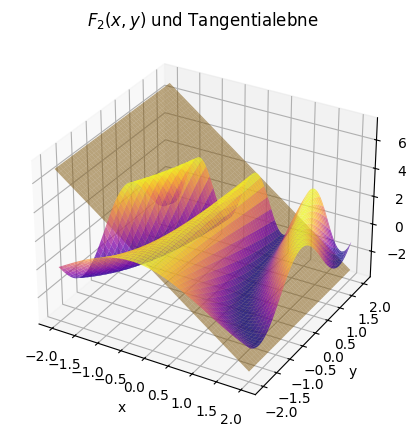

In [4]:
f0 = F(x0, y0)
J0 = DF(x0, y0)
X, Y = np.meshgrid(np.linspace(-2, 2, 100), np.linspace(-2, 2, 100))
Z2 = F(X, Y)[1]
T2 = f0[1] + J0[1, 0] * (X - x0) + J0[1, 1] * (Y - y0)

fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(122, projection="3d")
ax.plot_surface(X, Y, Z2, cmap="plasma", alpha=0.75)
ax.plot_surface(X, Y, T2, color="orange", alpha=0.5)
ax.scatter(x0, y0, f0[1], color="red", s=40)
ax.set_title(r"$F_2(x,y)$ und Tangentialebne")
ax.set_xlabel("x")
ax.set_ylabel("y")

Nun berechnen wir mit der Formel für das $d$-dimensionale Newton-Verfahren (slides, skript) jeweils iterativ das nächste $x_{i+1}$, bis unsere Annäherung gut genug ist. 

In [11]:
x_vec = [np.array((x0, y0))]
atol = 1e-15
delta = 0.8

for i in range(n_max):
    coords = x_vec[-1]
    print(f"norm(F({coords})) = {np.linalg.norm(F(*coords))}")
    if np.linalg.norm(F(*coords)) < atol:
        break

    J = DF(*coords)
    Q, R = np.linalg.qr(J)
    
    A = np.linalg.solve(R, Q.T @ F(*coords))

    new_x = coords - A
    # new_x = coords - delta * A
    x_vec.append(new_x)
    

norm(F([0 0])) = 2.6744227582019384
norm(F([ 0.72834662 -0.5908859 ])) = 1.2364244213436437
norm(F([ 0.32029762 -0.20710284])) = 0.48907132776120804
norm(F([ 0.42226556 -0.30888533])) = 0.010455168720208711
norm(F([ 0.42456966 -0.31118943])) = 1.052251575847861e-05
norm(F([ 0.42457199 -0.31119176])) = 1.0798718362887682e-11
norm(F([ 0.42457199 -0.31119176])) = 8.47036427205765e-16
